In [1]:
print('Hello APEX 🚀')

Hello APEX 🚀


# Customer Churn Prediction

## Business Problem

Telecom companies lose customers every month.

If we can predict which customers are likely to leave, the company can proactively offer discounts, better customer support, or loyalty benefits to retain them.

## Goal

Build a Machine Learning model that predicts whether a customer will churn.

## Success Metric

Accurately identify customers who are likely to churn.

## Business Impact

Reducing churn increases customer retention, revenue, and long-term profitability.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
f

SyntaxError: invalid syntax (2789700021.py, line 1)

In [3]:
df = pd.read_csv("../dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [9]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Observation

- The dataset contains 7043 customer records.
- The dataset has 21 columns (features).
- Each row represents one customer.
- Each column contains information about that customer.


# DATA CLEANING 

<Axes: xlabel='Churn', ylabel='count'>

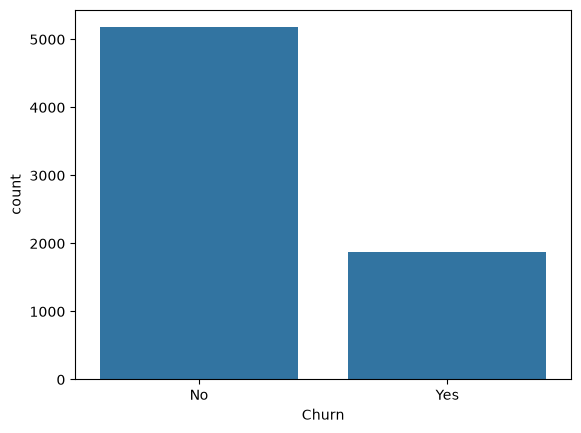

In [10]:
sns.countplot(x="Churn",data = df)

In [11]:
df["TotalCharges"].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str

In [12]:
type(df["TotalCharges"][0])

str

In [13]:
df[df["TotalCharges"] == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [14]:
(df["TotalCharges"].str.strip() == "").sum()

np.int64(11)

*** In this dataset there are 11 row where `TotalCharges` contains ( `"" empty strings`) thats why pandas treating whole 'TotalCharges'
column as `string`

In [15]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"], errors='coerce')

 ** Converting `string to numeric values` and `"" empty strings to nah "null values"`

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [17]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

## Data Cleaning Observation

- The `TotalCharges` column was stored as a string.
- Investigation revealed 11 empty string values.
- These values were converted to `NaN` using `pd.to_numeric(errors="coerce")`.
- The column was successfully converted to a numeric (`float64`) data type.

In [18]:
df.dropna(inplace=True)

In [19]:
df.shape

(7032, 21)

In [20]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df["Churn"].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

In [23]:
df["Churn"].value_counts(normalize= True)*100

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64

In [24]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7032,7032,7032.000000,7032,7032,7032.000000,7032,7032,7032,7032,...,7032,7032,7032,7032,7032,7032,7032,7032.000000,7032.000000,7032
unique,7032,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,NaN,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,1,3549,NaN,3639,4933,NaN,6352,3385,3096,3497,...,3094,3472,2809,2781,3875,4168,2365,NaN,NaN,5163
mean,NaN,NaN,0.162400,NaN,NaN,32.421786,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.798208,2283.300441,NaN
std,NaN,NaN,0.368844,NaN,NaN,24.545260,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.085974,2266.771362,NaN
min,NaN,NaN,0.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,18.800000,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.587500,401.450000,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,1397.475000,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.862500,3794.737500,NaN


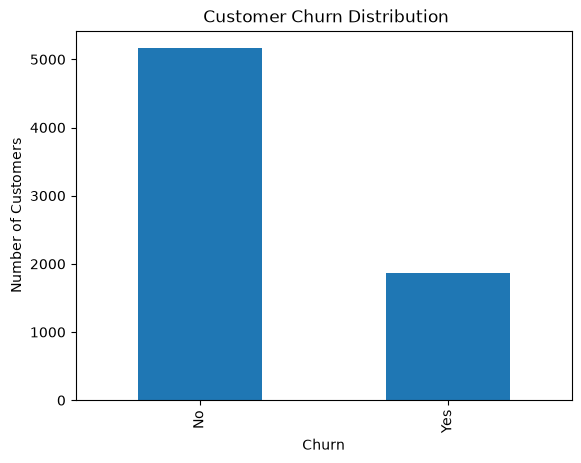

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

df["Churn"].value_counts().plot(kind="bar")
plt.title(" Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

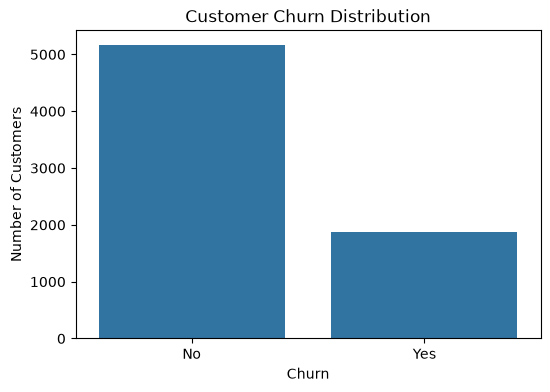

In [26]:
plt.figure(figsize=(6,4))
sns.countplot(x="Churn",data=df)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [27]:
df["MonthlyCharges"].describe()

count    7032.000000
mean       64.798208
std        30.085974
min        18.250000
25%        35.587500
50%        70.350000
75%        89.862500
max       118.750000
Name: MonthlyCharges, dtype: float64

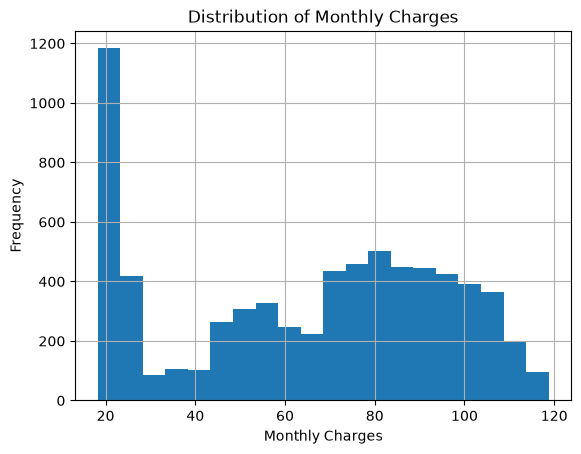

In [28]:
df["MonthlyCharges"].hist(bins=20)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Frequency")

plt.show()

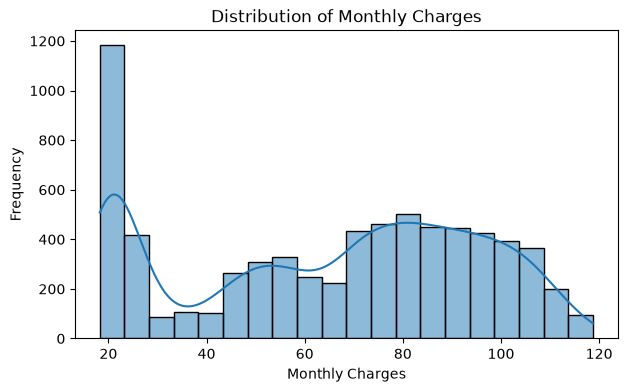

In [29]:
plt.figure(figsize=(7,4))

sns.histplot(df["MonthlyCharges"], bins=20, kde=True)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Frequency")
plt.show()

In [30]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.307408
Yes    74.441332
Name: MonthlyCharges, dtype: float64

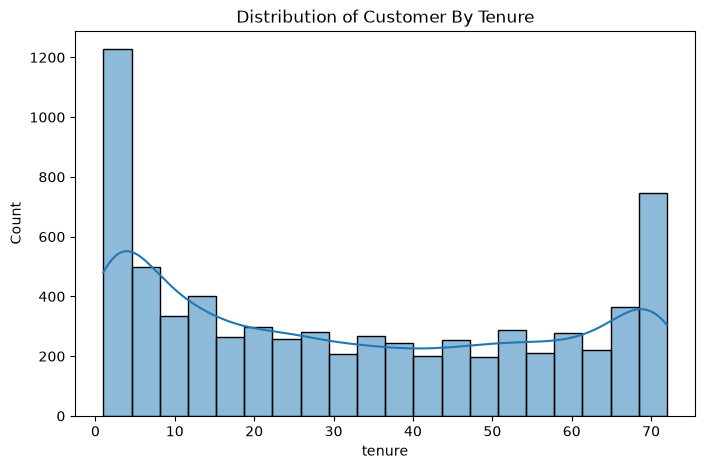

In [31]:
plt.figure(figsize=(8,5))

sns.histplot(df["tenure"],bins=20, kde=True)
plt.title("Distribution of Customer By Tenure")
plt.show()

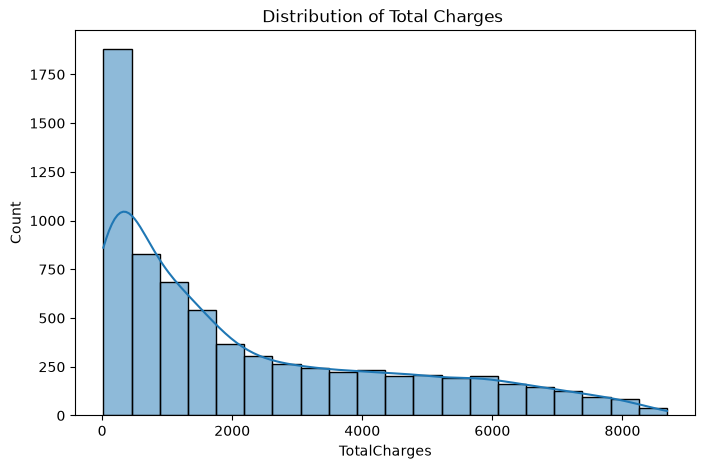

In [32]:
plt.figure(figsize=(8,5))

sns.histplot(df["TotalCharges"],bins=20, kde=True)
plt.title("Distribution of Total Charges ")
plt.show()

<Figure size 600x400 with 0 Axes>

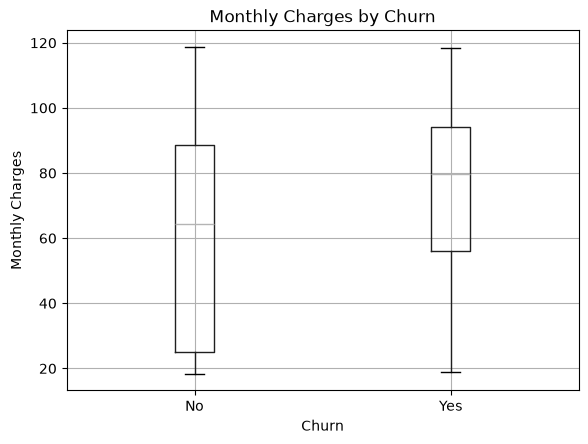

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

df.boxplot(column="MonthlyCharges", by="Churn")

plt.title("Monthly Charges by Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

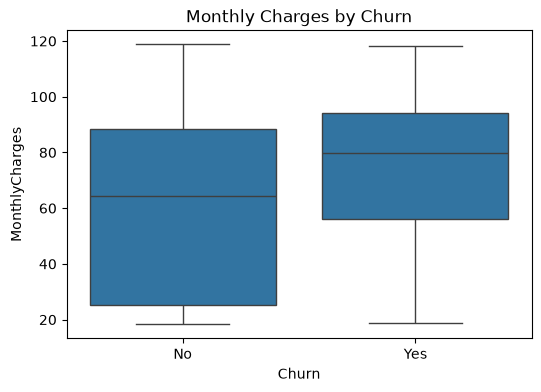

In [34]:
plt.figure(figsize=(6,4))

sns.boxplot(
    x="Churn",
    y="MonthlyCharges",
    data=df
)
plt.title("Monthly Charges by Churn")
plt.show()

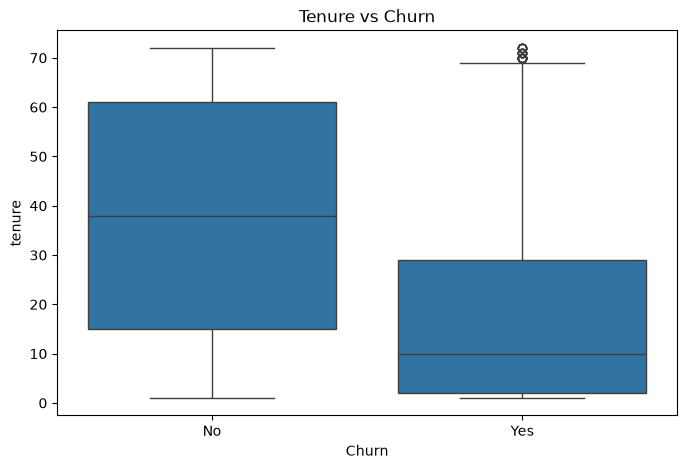

In [35]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="Churn",
    y="tenure",
    data=df
)
plt.title("Tenure vs Churn")
plt.show()

# Categorical EDA 

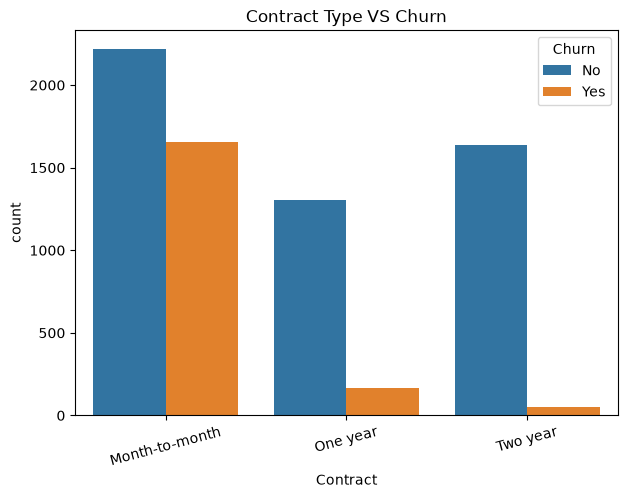

In [36]:
plt.figure(figsize=(7,5))

sns.countplot(
    x="Contract",
    hue="Churn",
    data=df
)
plt.title("Contract Type VS Churn")
plt.xticks(rotation=15)
plt.show()

<Axes: xlabel='InternetService', ylabel='count'>

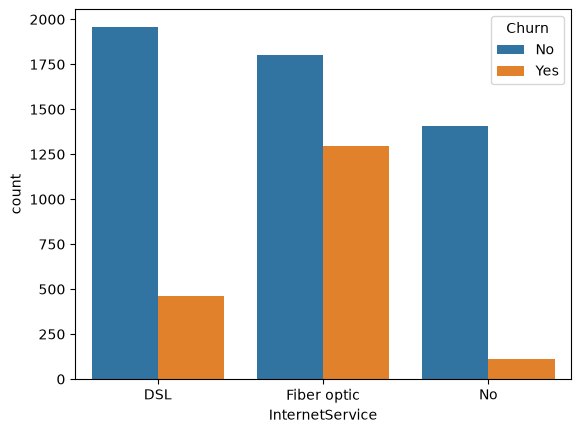

In [37]:
sns.countplot(
    x="InternetService",
    hue="Churn",
    data=df
)

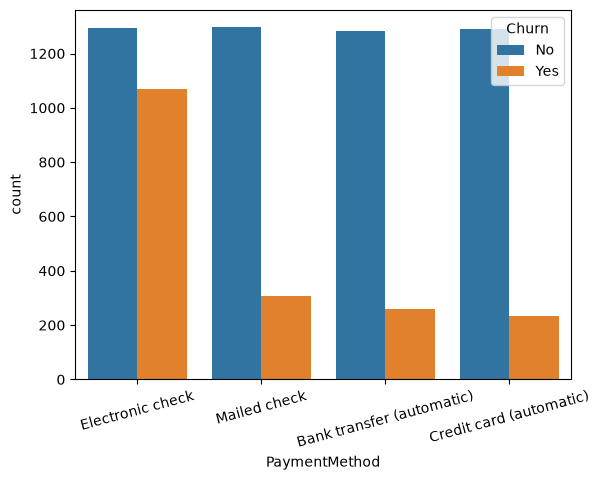

In [38]:
sns.countplot(
    x="PaymentMethod",
    hue="Churn",
    data=df
)
plt.xticks(rotation=15)
plt.show()

<Axes: xlabel='gender', ylabel='count'>

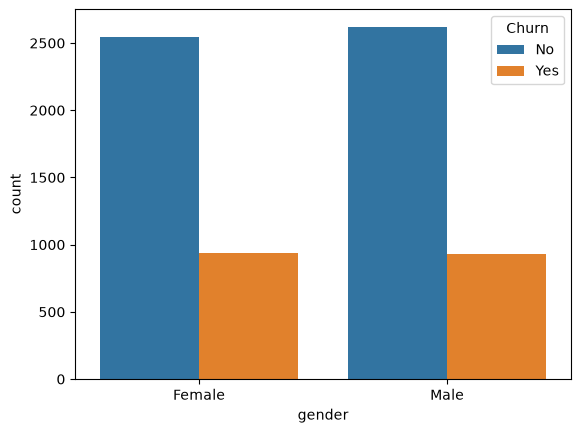

In [39]:
sns.countplot(
    x="gender",
    hue="Churn",
    data=df
)

<Axes: xlabel='SeniorCitizen', ylabel='count'>

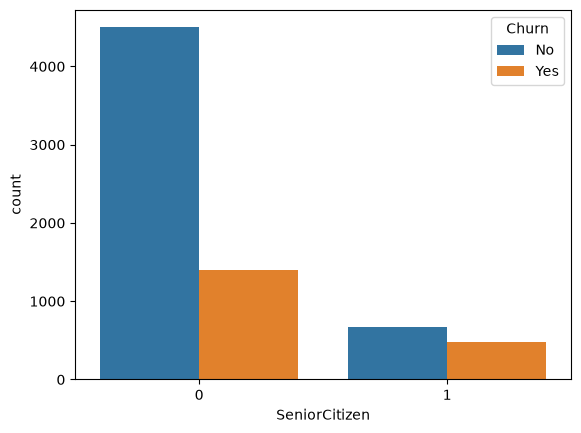

In [40]:
sns.countplot(
    x="SeniorCitizen",
    hue="Churn",
    data=df
)

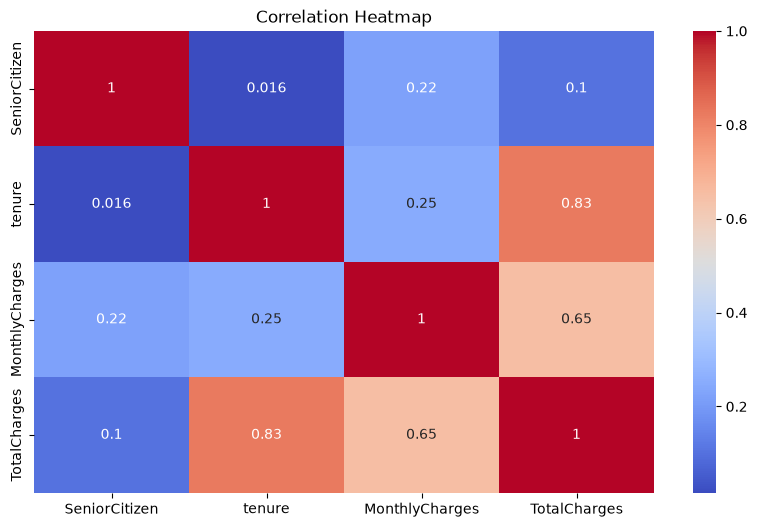

In [41]:
plt.figure(figsize=(10,6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()

# Block 2 practise Feature enginnering 


## Feature Engineering Observation

- Customers in the first year have the highest churn rate (~47%).
- As customer tenure increases, churn decreases significantly.
- Customers who stay for more than 4 years have the lowest churn (~10%).
- This suggests that retaining customers during their first year is critical for reducing overall churn.

In [42]:
df["tenure_group"]=pd.cut(
    df["tenure"],
    bins=[0,12,24,48,72],
    labels=["New Customers","Regular Customers","Loyal Customers","LongTerm Customers"]
)

                        
                           

In [43]:
df["MonthlyCharges"].quantile([0.25,0.50,0.75])

0.25    35.5875
0.50    70.3500
0.75    89.8625
Name: MonthlyCharges, dtype: float64

In [44]:
df["MonthlyChargeBucket"]=pd.cut (
    df["MonthlyCharges"],
    bins = [0,35,70,120],
    labels = ["Low ","Medium","High"],
    include_lowest=True
)

In [45]:
df[["MonthlyCharges","MonthlyChargeBucket"]].head(15)

,MonthlyCharges,MonthlyChargeBucket
0,29.85,Low
1,56.95,Medium
2,53.85,Medium
3,42.30,Medium
4,70.70,High
5,99.65,High
6,89.10,High
7,29.75,Low
8,104.80,High
9,56.15,Medium


In [46]:
df["MonthlyChargeBucket"].value_counts()

MonthlyChargeBucket
High      3581
Low       1729
Medium    1722
Name: count, dtype: int64

In [47]:
df.groupby("MonthlyChargeBucket")["Churn"].value_counts()

MonthlyChargeBucket  Churn
Low                  No       1540
                     Yes       189
Medium               No       1309
                     Yes       413
High                 No       2314
                     Yes      1267
Name: count, dtype: int64

In [48]:
from sklearn.preprocessing import LabelEncoder

In [49]:
binary_columns = ["gender","Partner","Dependents","PhoneService","PaperlessBilling","Churn"]

le = LabelEncoder()

for col in binary_columns:
    df[col] = le.fit_transform(df[col])

In [50]:
df[binary_columns].head()

,gender,Partner,Dependents,PhoneService,PaperlessBilling,Churn
0,0,1,0,0,1,0
1,1,0,0,1,0,0
2,1,0,0,1,1,1
3,1,0,0,0,0,0
4,0,0,0,1,1,1


In [51]:
categorical_columns = ["Contract","InternetService","PaymentMethod","tenure_group","MonthlyChargeBucket"]



In [52]:
df = pd.get_dummies(df, columns=categorical_columns, drop_first=True)

# Model traning 

# Logistic Regression 


In [53]:
df=df.drop("customerID",axis=1)

In [54]:
df["MultipleLines"] = df["MultipleLines"].map({
    "No":0,
    "Yes":1,
    "No phone service": 0
})

In [55]:
yes_no_columns =["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]

for col in yes_no_columns:
    df[col]=df[col].map({
        "No": 0,
        "Yes": 1,
        "No internet service": 0
    })

In [56]:
df[[
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]].head()

,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,0,0,1,0,0,0,0
1,0,1,0,1,0,0,0
2,0,1,1,0,0,0,0
3,0,1,0,1,1,0,0
4,0,0,0,0,0,0,0


In [57]:
x= df.drop("Churn",axis=1)
y= df["Churn"]

In [58]:
print(x.shape)
print(y.shape)

(7032, 28)
(7032,)


In [59]:
from sklearn.model_selection import train_test_split 

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=69)

In [60]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)



In [61]:
x_train.select_dtypes(include="object").columns

Index([], dtype='str')

In [62]:
from sklearn.linear_model import LogisticRegression  
log_model = LogisticRegression(max_iter=1000)
log_model.fit(x_train_scaled,y_train)



,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [63]:
y_pred = log_model.predict(x_test_scaled)

In [64]:
print(y_pred[0:20])

[1 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0]


In [65]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8002842928216063


In [66]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_pred)
print(cm)


[[917 113]
 [168 209]]


In [67]:
from sklearn.metrics import precision_score, recall_score, f1_score
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1 score:", f1)


Precision: 0.6490683229813664
Recall: 0.5543766578249337
F1 score: 0.597997138769671


# Decision Tree and Random Forest 

In [68]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(random_state=69)

In [69]:
dt_model.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",69
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [70]:
y_pred_dt = dt_model.predict(x_test)

In [71]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
accuracy_dt = accuracy_score(y_test,y_pred_dt)
precision_dt = precision_score(y_test,y_pred_dt)
recall_dt = recall_score(y_test,y_pred_dt)
f1_dt = f1_score(y_test,y_pred_dt)

print("Accuracy", accuracy_dt)
print("Precision", precision_dt)
print("Recall", recall_dt)
print("F1 Score", f1_dt)


Accuracy 0.7249466950959488
Precision 0.48655913978494625
Recall 0.48010610079575594
F1 Score 0.4833110814419226


# random forest 

In [72]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=69)

In [73]:
rf_model.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",69
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [74]:
y_pred_rf = rf_model.predict(x_test)

In [75]:
accuracy_rf = accuracy_score(y_test,y_pred_rf)
precision_rf = precision_score(y_test,y_pred_rf)
recall_rf = recall_score(y_test,y_pred_rf)
f1_rf = f1_score(y_test,y_pred_rf)

print("Accuracy", accuracy_rf)
print("Precision",precision_rf)
print("Recall",recall_rf)
print("F1 Score",f1_rf)


Accuracy 0.7775408670931059
Precision 0.6073825503355704
Recall 0.48010610079575594
F1 Score 0.5362962962962963


Logistic Regression performed best among the three baseline models, achieving the highest accuracy, precision, recall, and F1 score. However, Random Forest will be further investigated through feature importance and hyperparameter tuning before making the final model selection.

In [76]:
feature_importance = rf_model.feature_importances_

In [77]:
features = x_train.columns 


In [78]:
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(by="Importance",ascending=False)

importance_df.head(10)

,Feature,Importance
15,TotalCharges,0.191325
14,MonthlyCharges,0.169744
4,tenure,0.152180
21,PaymentMethod_Electronic check,0.038189
18,InternetService_Fiber optic,0.037481
17,Contract_Two year,0.029465
0,gender,0.028556
13,PaperlessBilling,0.025673
16,Contract_One year,0.023129
2,Partner,0.022983


In [79]:
feature_importance = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": x_train.columns,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(by= "Importance",ascending=False)
importance_df.head(10)

,Feature,Importance
15,TotalCharges,0.191325
14,MonthlyCharges,0.169744
4,tenure,0.152180
21,PaymentMethod_Electronic check,0.038189
18,InternetService_Fiber optic,0.037481
17,Contract_Two year,0.029465
0,gender,0.028556
13,PaperlessBilling,0.025673
16,Contract_One year,0.023129
2,Partner,0.022983


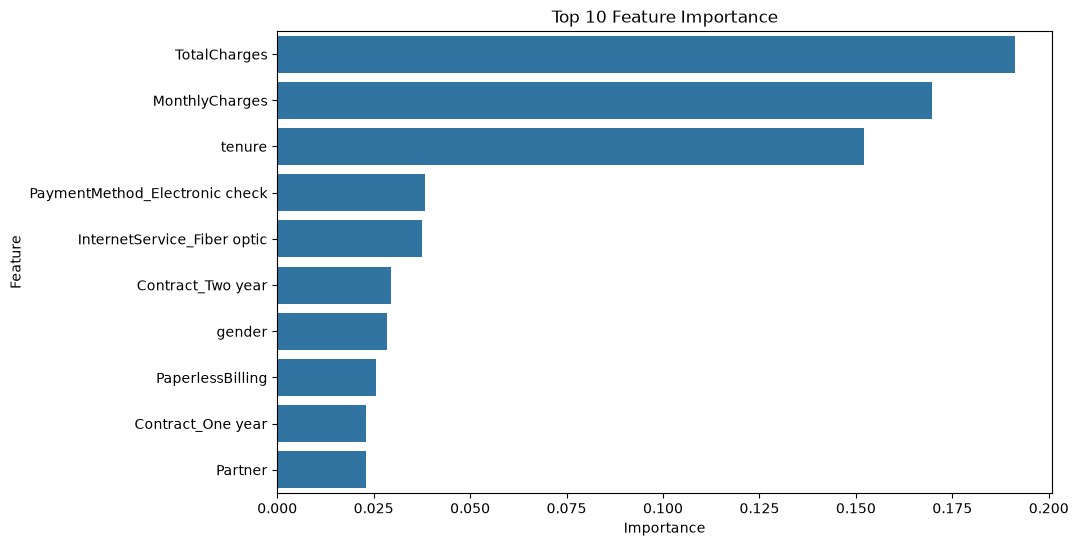

In [80]:
plt.figure(figsize=(10,6))

sns.barplot(
    x="Importance",
    y="Feature",
    data=importance_df.head(10)

)

plt.title("Top 10 Feature Importance")
plt.show()

In [81]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier


In [82]:
rf = RandomForestClassifier(random_state=69)

In [83]:
param_grid={
    "n_estimators":[100,200,300,400,500],
    "max_depth":[None,5,10,15,20],
    "min_samples_split":[2,5,10],
    "min_samples_leaf":[1,2,4]
}

In [84]:
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=12,
    scoring="recall",
    cv=5,
    random_state=69,
    n_jobs=-1
)

In [85]:
random_search.fit(x_train,y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=69)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",12
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",69
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for m

In [86]:
print("Best Parameters:")
print(random_search.best_params_)

Best Parameters:
{'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 15}


In [87]:
print("Best CV Recall:")
print(random_search.best_score_)

Best CV Recall:
0.5100760925680681


In [88]:
best_rf= random_search.best_estimator_

In [89]:
y_pred_tuned = best_rf.predict(x_test)

In [90]:
accuracy_tuned = accuracy_score(y_test,y_pred_tuned)
precision_tuned = precision_score(y_test,y_pred_tuned)
recall_tuned = recall_score(y_test,y_pred_tuned)
f1_tuned = f1_score(y_test,y_pred_tuned)

print("Accuracy:",accuracy_tuned)
print("precision:",precision_tuned)
print("recall:",recall_tuned)
print("F1 Score:",f1_tuned)


Accuracy: 0.7896233120113717
precision: 0.6327868852459017
recall: 0.5119363395225465
F1 Score: 0.5659824046920822


## ROC Curve + AUC

for logistic regression 

In [91]:
y_prob = log_model.predict_proba(x_test_scaled)[:,1]

[:,1] = churn ki probability  
no churn    
0.80   
0.30

churn 
0.20
0.70      

In [92]:
print(y_prob[0:10])

[0.59140326 0.72212684 0.38947505 0.40267144 0.02235372 0.01690063
 0.09807222 0.00980861 0.05876772 0.24399616]


In [93]:
from sklearn.metrics import roc_curve , roc_auc_score
fpr, tpr, thresholds = roc_curve(y_test,y_prob)
auc = roc_auc_score(y_test,y_prob)
print("AUC:",auc)


AUC: 0.8464718910149107


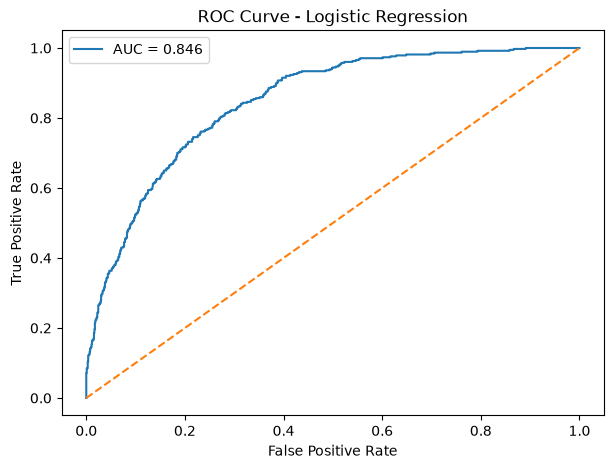

In [94]:
plt.figure(figsize=(7,5))
plt.plot(fpr,tpr,label=f"AUC = {auc:.3f}")
plt.plot([0, 1],[0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")

plt.legend()
plt.show()


different threshold check karna 


In [95]:
import numpy as np 
from sklearn.metrics import precision_score , recall_score, f1_score
thresholds_to_test = [0.3,0.4,0.5,0.6,0.7]

for threshold in thresholds_to_test:
    y_pred_threshold = (y_prob >= threshold).astype(int)
    precision = precision_score(y_test,y_pred_threshold)
    recall = recall_score(y_test,y_pred_threshold)
    f1 = f1_score(y_test,y_pred_threshold)

    print(f"Threshold: {threshold} | " 
          f"Precision: {precision:.3f} | "
          f"Recall: {recall:.3f} | "
          f"F1-Score: {f1:.3f}")

Threshold: 0.3 | Precision: 0.529 | Recall: 0.772 | F1-Score: 0.628
Threshold: 0.4 | Precision: 0.582 | Recall: 0.671 | F1-Score: 0.623
Threshold: 0.5 | Precision: 0.649 | Recall: 0.554 | F1-Score: 0.598
Threshold: 0.6 | Precision: 0.704 | Recall: 0.385 | F1-Score: 0.497
Threshold: 0.7 | Precision: 0.800 | Recall: 0.244 | F1-Score: 0.374


I lowered the classification threshold from 0.5 to 0.3 because in customer churn prediction, missing a potential churner can be costly. This increased recall from 55.4% to 77.2%, while precision decreased from 64.9% to 52.9%. The F1 score also improved from 59.8% to 62.8%."

In [96]:
from sklearn.metrics import accuracy_score 
y_pred_03 = (y_prob >=0.3).astype(int)
accuracy_03 = accuracy_score(y_test,y_pred_03)
print("Accuracy at 0.3:", accuracy_03)

Accuracy at 0.3: 0.7547974413646056


Confusion Matrix:
[[771 259]
 [ 86 291]]


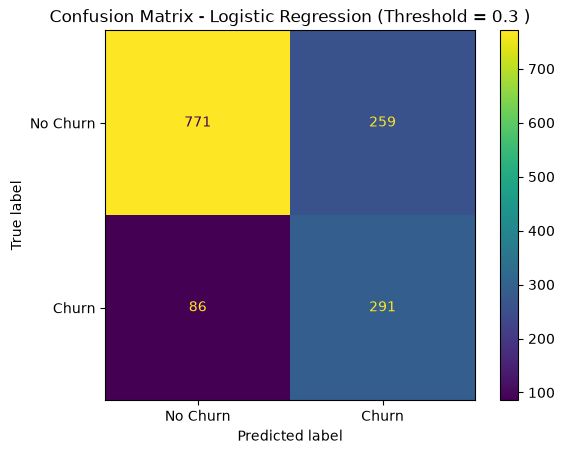

In [97]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt 

cm_03 = confusion_matrix(y_test,y_pred_03)
print("Confusion Matrix:")
print(cm_03)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_03, display_labels=["No Churn", "Churn"])
disp.plot()
plt.title("Confusion Matrix - Logistic Regression (Threshold = 0.3 )")
plt.show()


In [98]:
tn, fp, fn, tp = cm_03.ravel()

print("true negative:", tn )
print("false positive:", fp )
print("false negative:", fn )
print("true positive:", tp )

print("\nTotal customers:", len(y_test))

print("Actual churners:", fn+tp)
print("Actual non-churners:", tn+fp)

print("Predicted churners:", fp+tp)
print("Predicted non-churners:", tn+fn)

true negative: 771
false positive: 259
false negative: 86
true positive: 291

Total customers: 1407
Actual churners: 377
Actual non-churners: 1030
Predicted churners: 550
Predicted non-churners: 857


In [99]:
precision_manual = tp/ (tp + fp)
recall_manual = tp / (tp + fn )
accuracy_manual = (tp+tn)/ (tp+tn+fp+fn)

print("Precision:", precision_manual)
print("Recall:",recall_manual)
print("Accuracy:",accuracy_manual)

Precision: 0.5290909090909091
Recall: 0.7718832891246684
Accuracy: 0.7547974413646056


In [100]:
import pandas as pd 
threshold_comparison = pd.DataFrame({
    "Threshold":[0.3,0.5],
    "Accuracy":[accuracy_03, 0.8003],
    "Precision":[precision_manual, 0.6491],
    "Recall":[recall_manual, 0.5544],
    "F1 Score":[0.628,0.5980]

})
threshold_comparison


,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.3,0.754797,0.529091,0.771883,0.628
1,0.5,0.800300,0.649100,0.554400,0.598


In [101]:
threshold_comparison.round(3)

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.3,0.755,0.529,0.772,0.628
1,0.5,0.800,0.649,0.554,0.598


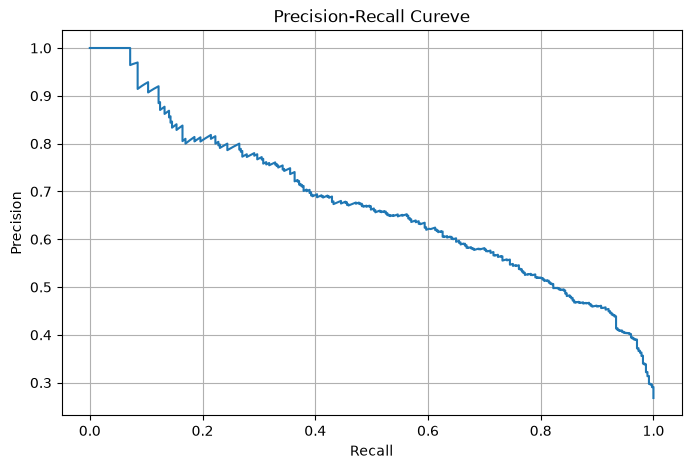

In [102]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision , recall , thresholds = precision_recall_curve(
    y_test,
    y_prob
)
plt.figure(figsize=(8, 5))
plt.plot(recall,precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Cureve")
plt.grid(True)

plt.show()

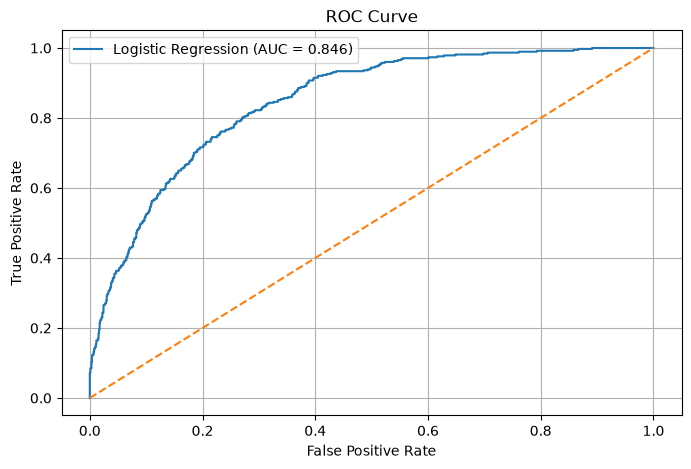

ROC-AUC: 0.8464718910149107


In [103]:
from sklearn.metrics import roc_curve,roc_auc_score
import matplotlib.pyplot as plt 

fpr, tpr , roc_thresholds = roc_curve(y_test,y_prob)
roc_auc = roc_auc_score(y_test,y_prob)
plt.figure(figsize=(8,5))
plt.plot(fpr,tpr,label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0,1],[0,1],linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()
print("ROC-AUC:",roc_auc)

In [104]:
from sklearn.metrics import average_precision_score
pr_auc = average_precision_score(y_test,y_prob)
print("PR-AUC:",pr_auc)

PR-AUC: 0.6723588825383335


### My Prediction

Before calculating feature importance, I expect the most influential
features to be related to customer tenure, monthly charges, total charges,
and/or contract characteristics based on the earlier EDA.

### RANDOM FOREST FEATURES IMPORTANCE


In [105]:
feature_importance = rf_model.feature_importances_
features = x_train.columns

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)
importance_df.head(10)

,Feature,Importance
15,TotalCharges,0.191325
14,MonthlyCharges,0.169744
4,tenure,0.152180
21,PaymentMethod_Electronic check,0.038189
18,InternetService_Fiber optic,0.037481
17,Contract_Two year,0.029465
0,gender,0.028556
13,PaperlessBilling,0.025673
16,Contract_One year,0.023129
2,Partner,0.022983


top 10 visualization 

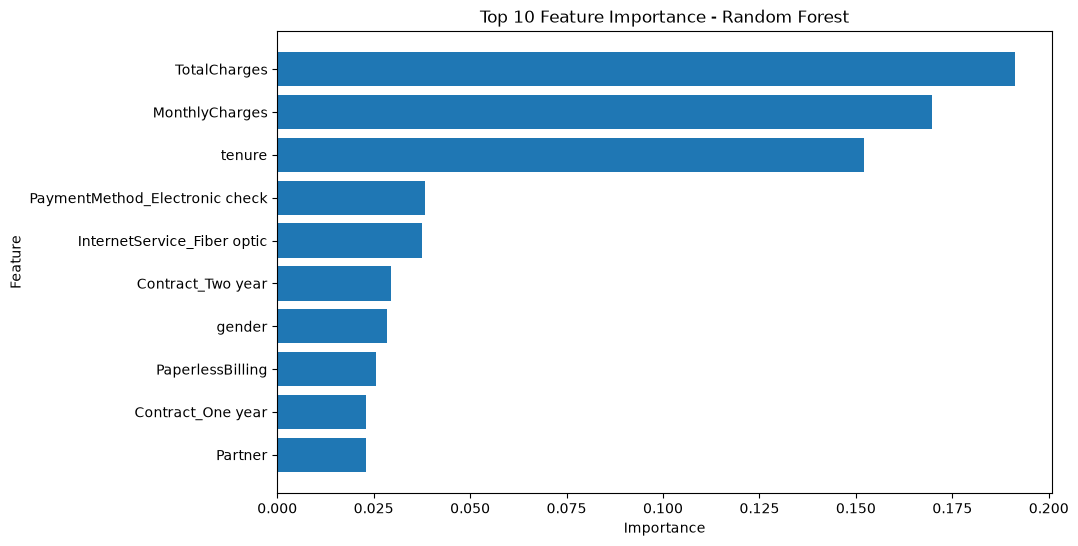

In [106]:
import matplotlib.pyplot as plt 
top10 = importance_df.head(10)
plt.figure(figsize=(10,6))
plt.barh(
    top10["Feature"][::-1],
    top10["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importance - Random Forest")
plt.show()

checking actual importance values

In [107]:
importance_df.head(10).round(4)

,Feature,Importance
15,TotalCharges,0.1913
14,MonthlyCharges,0.1697
4,tenure,0.1522
21,PaymentMethod_Electronic check,0.0382
18,InternetService_Fiber optic,0.0375
17,Contract_Two year,0.0295
0,gender,0.0286
13,PaperlessBilling,0.0257
16,Contract_One year,0.0231
2,Partner,0.0230


In [108]:
print("Total importance:",importance_df["Importance"].sum())

Total importance: 1.0


aab hum dekhange ki top 5 10 15 feature milkar model ki kitney importance explain kar rahe 

In [109]:
importance_df["Cumulative_Importance"]=(
    importance_df["Importance"].cumsum()
)
importance_df.head(20)

,Feature,Importance,Cumulative_Importance
15,TotalCharges,0.191325,0.191325
14,MonthlyCharges,0.169744,0.361069
4,tenure,0.152180,0.513249
21,PaymentMethod_Electronic check,0.038189,0.551439
18,InternetService_Fiber optic,0.037481,0.588920
17,Contract_Two year,0.029465,0.618385
0,gender,0.028556,0.646942
13,PaperlessBilling,0.025673,0.672614
16,Contract_One year,0.023129,0.695743
2,Partner,0.022983,0.718726


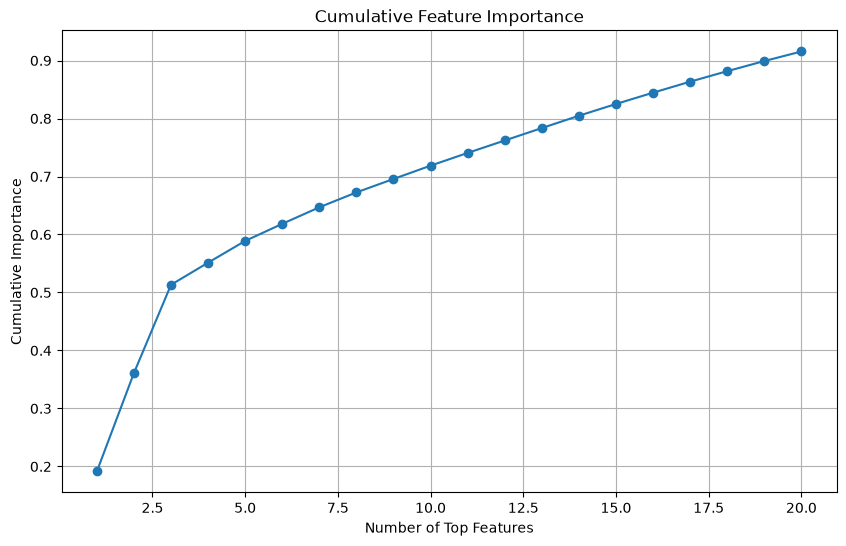

In [110]:
top20 = importance_df.head(20)
plt.figure(figsize=(10,6))
plt.plot(
    range(1,len(top20)+1),
    top20["Cumulative_Importance"],
    marker="o"
)

plt.xlabel("Number of Top Features")
plt.ylabel("Cumulative Importance")
plt.title("Cumulative Feature Importance")
plt.grid(True)
plt.show()

Suppose model accuracy/F1 is currently good.

Now randomly shuffle one feature.

If model performance drops significantly, that feature was useful.

If performance barely changes:

Model didn't rely heavily on that feature.

In [111]:
from sklearn.inspection import permutation_importance
prem_result = permutation_importance(
    rf_model,
    x_test,
    y_test,
    n_repeats=10,
    random_state=69,
    scoring="f1"
)

In [112]:
perm_importance_df = pd.DataFrame({
    "Feature":x_test.columns,
    "Importance":prem_result.importances_mean
})

perm_importance_df = perm_importance_df.sort_values(
    by="Importance",
    ascending=False
)
perm_importance_df.head(10)

,Feature,Importance
4,tenure,0.049587
18,InternetService_Fiber optic,0.044240
17,Contract_Two year,0.033829
14,MonthlyCharges,0.024518
16,Contract_One year,0.019667
15,TotalCharges,0.018050
13,PaperlessBilling,0.015429
6,MultipleLines,0.008191
1,SeniorCitizen,0.006827
10,TechSupport,0.005356


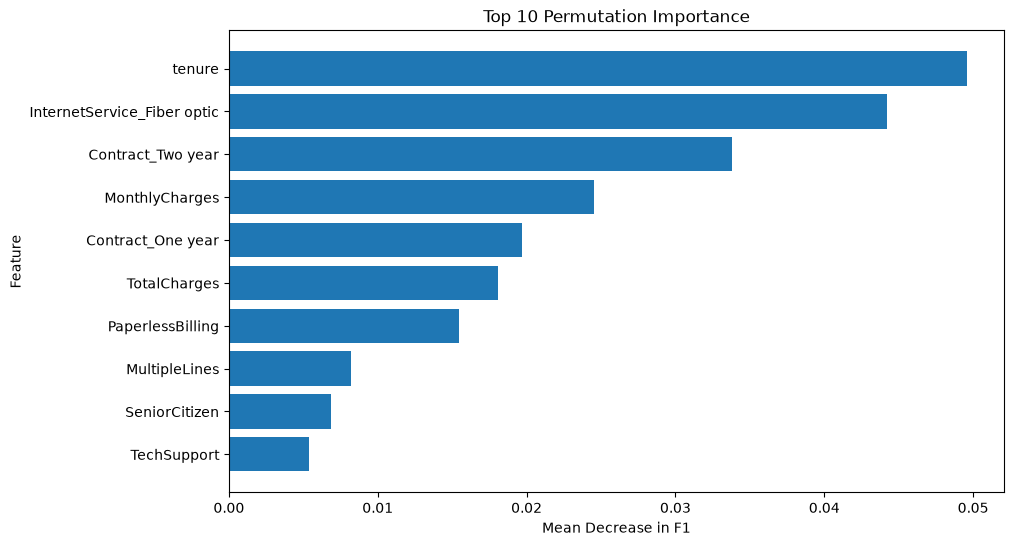

In [113]:
top10_perm=perm_importance_df.head(10)
plt.figure(figsize=(10,6))
plt.barh(
    top10_perm["Feature"][::-1],
    top10_perm["Importance"][::-1]
)

plt.xlabel("Mean Decrease in F1")
plt.ylabel("Feature")
plt.title("Top 10 Permutation Importance")
plt.show()

In [114]:
comparison_importance = importance_df[
    ["Feature", "Importance"]
].head(10).copy()
comparison_importance.rename(
    columns={"Importance":"RandomForest_Importance"},
    inplace=True
)
comparison_importance 

,Feature,RandomForest_Importance
15,TotalCharges,0.191325
14,MonthlyCharges,0.169744
4,tenure,0.152180
21,PaymentMethod_Electronic check,0.038189
18,InternetService_Fiber optic,0.037481
17,Contract_Two year,0.029465
0,gender,0.028556
13,PaperlessBilling,0.025673
16,Contract_One year,0.023129
2,Partner,0.022983


In [115]:
perm_importance_df.head(10)

,Feature,Importance
4,tenure,0.049587
18,InternetService_Fiber optic,0.044240
17,Contract_Two year,0.033829
14,MonthlyCharges,0.024518
16,Contract_One year,0.019667
15,TotalCharges,0.018050
13,PaperlessBilling,0.015429
6,MultipleLines,0.008191
1,SeniorCitizen,0.006827
10,TechSupport,0.005356


🔥 Business team ko hum kya bol sakte hain?

Based on these findings, company could investigate:

1. High monthly-charge customers
→ Are they experiencing pricing/value concerns?

2. New vs long-tenure customers
→ Are newer customers leaving more frequently?

3. Electronic-check customers
→ Is there any payment experience/friction associated with this segment?

4. Fiber-optic customers
→ Are there service-quality or support issues worth investigating?

In [116]:
top10_features = importance_df.head(10).copy()
top10_features

,Feature,Importance,Cumulative_Importance
15,TotalCharges,0.191325,0.191325
14,MonthlyCharges,0.169744,0.361069
4,tenure,0.152180,0.513249
21,PaymentMethod_Electronic check,0.038189,0.551439
18,InternetService_Fiber optic,0.037481,0.588920
17,Contract_Two year,0.029465,0.618385
0,gender,0.028556,0.646942
13,PaperlessBilling,0.025673,0.672614
16,Contract_One year,0.023129,0.695743
2,Partner,0.022983,0.718726


In [117]:
top10_features["Importance"]=(
    top10_features["Importance"].round(4)
)
top10_features

,Feature,Importance,Cumulative_Importance
15,TotalCharges,0.1913,0.191325
14,MonthlyCharges,0.1697,0.361069
4,tenure,0.1522,0.513249
21,PaymentMethod_Electronic check,0.0382,0.551439
18,InternetService_Fiber optic,0.0375,0.588920
17,Contract_Two year,0.0295,0.618385
0,gender,0.0286,0.646942
13,PaperlessBilling,0.0257,0.672614
16,Contract_One year,0.0231,0.695743
2,Partner,0.0230,0.718726


In [118]:
import shap 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [119]:
pip install shap


Note: you may need to restart the kernel to use updated packages.


In [120]:
!python3 -m pip install --upgrade pip

In [121]:
rf_model

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",69
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [122]:
print(rf_model)
print("Train shape:", x_train.shape)
print("Test shape:", x_test.shape)

RandomForestClassifier(random_state=69)
Train shape: (5625, 28)
Test shape: (1407, 28)


In [123]:
print("Number of features:", x_test.shape[1])

Number of features: 28


In [124]:
explainer = shap.TreeExplainer(rf_model)

In [125]:
shap_values = explainer.shap_values(x_test)
print(type(shap_values))

<class 'numpy.ndarray'>


In [126]:
print("Type:", type(shap_values))

if isinstance(shap_values, list):
    print("Number of SHAP arrays:", len(shap_values))
    for i, arr in enumerate(shap_values):
        print(i, arr.shape)
    else:
        print("SHAP shape:", shap_values.shape)

Type: <class 'numpy.ndarray'>


In [127]:
if isinstance(shap_values,list):
    shap_churn = shap_values[1]
else:
    if len(shap_values.shape)==3:
        shap_churn = shap_values[:,:,1]
    else:
        shap_churn = shap_values

print("SHAP churn shape:",shap_churn.shape)
print("x_test shape:",x_test.shape)

SHAP churn shape: (1407, 28)
x_test shape: (1407, 28)


feature with largest average impact on prediction 

In [128]:
mean_abs_shap = np.abs(shap_churn).mean(axis=0)
shap_importance_df = pd.DataFrame({
    "Feature": x_test.columns,
    "Mean_ABS_SHAP":mean_abs_shap
})

shap_import_df = shap_importance_df.sort_values(
    by="Mean_ABS_SHAP",
    ascending=False
)
shap_importance_df.head(10)

,Feature,Mean_ABS_SHAP
0,gender,0.006726
1,SeniorCitizen,0.009191
2,Partner,0.005219
3,Dependents,0.007564
4,tenure,0.055423
5,PhoneService,0.003292
6,MultipleLines,0.010283
7,OnlineSecurity,0.015089
8,OnlineBackup,0.005656
9,DeviceProtection,0.004551


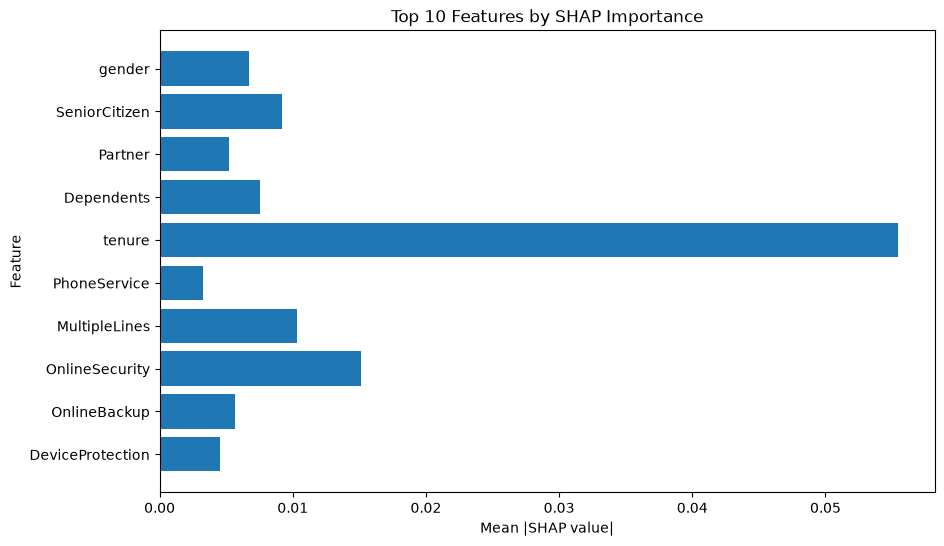

In [129]:
top10_shap = shap_importance_df.head(10)
plt.figure(figsize=(10,6))

plt.barh(
    top10_shap["Feature"][::-1],
    top10_shap["Mean_ABS_SHAP"][::-1]
)
plt.xlabel("Mean |SHAP value|")
plt.ylabel("Feature")
plt.title("Top 10 Features by SHAP Importance")

plt.show()

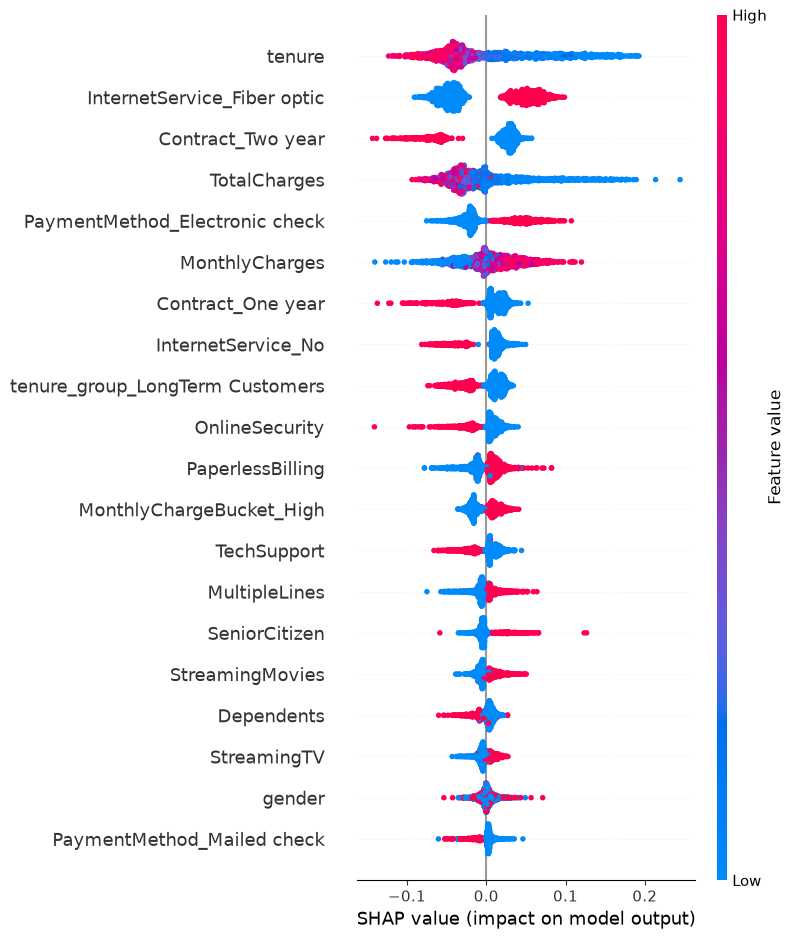

In [130]:
shap.summary_plot(
    shap_churn,
    x_test
)

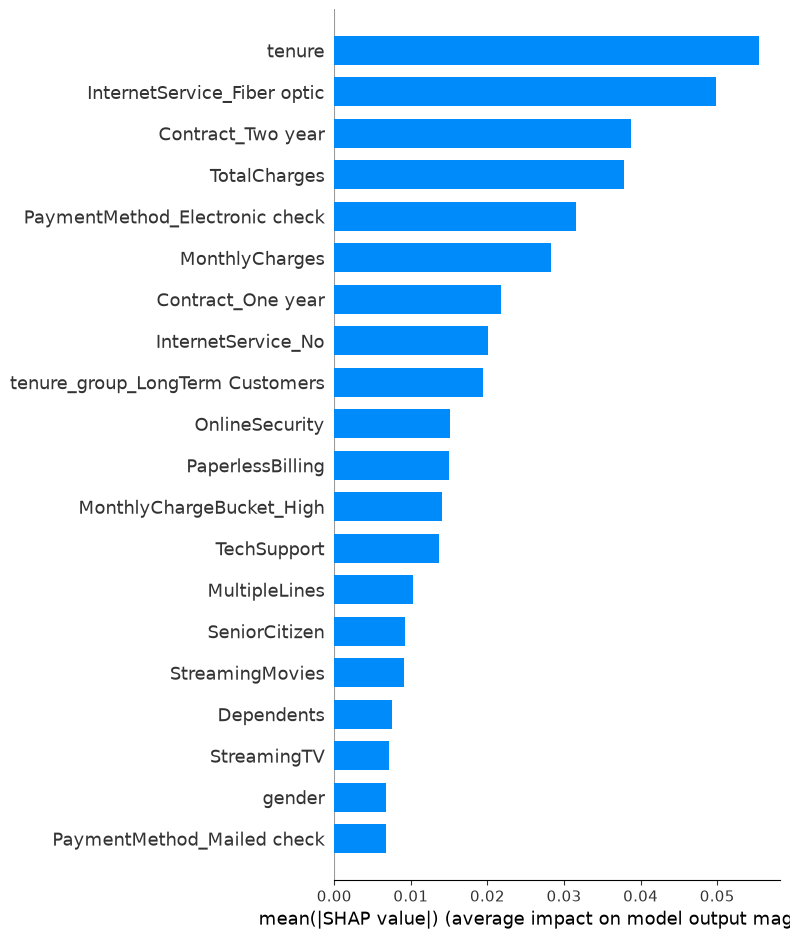

In [131]:
shap.summary_plot(
    shap_churn,
    x_test,
    plot_type="bar"
)

In [132]:
comparison  = importance_df[
    ["Feature", "Importance"]
].head(10).copy()

comparison.rename(
    columns={
        "Importance": "RF_Importance"
    },
    inplace=True
)

shap_top = shap_importance_df.head(10).copy()

shap_top.rename(
    columns={
        "Mean_ABS_SHAP":"SHAP_Importance"
    
    },
    inplace=True
)
comparison.head(10)

,Feature,RF_Importance
15,TotalCharges,0.191325
14,MonthlyCharges,0.169744
4,tenure,0.152180
21,PaymentMethod_Electronic check,0.038189
18,InternetService_Fiber optic,0.037481
17,Contract_Two year,0.029465
0,gender,0.028556
13,PaperlessBilling,0.025673
16,Contract_One year,0.023129
2,Partner,0.022983


In [133]:
shap_top.head(10)

,Feature,SHAP_Importance
0,gender,0.006726
1,SeniorCitizen,0.009191
2,Partner,0.005219
3,Dependents,0.007564
4,tenure,0.055423
5,PhoneService,0.003292
6,MultipleLines,0.010283
7,OnlineSecurity,0.015089
8,OnlineBackup,0.005656
9,DeviceProtection,0.004551


In [134]:
shap_importance_df = shap_importance_df.sort_values(
    by="Mean_ABS_SHAP",
    ascending=False
).reset_index(drop=True)

shap_importance_df.head(10)


,Feature,Mean_ABS_SHAP
0,tenure,0.055423
1,InternetService_Fiber optic,0.049827
2,Contract_Two year,0.038753
3,TotalCharges,0.037776
4,PaymentMethod_Electronic check,0.031588
5,MonthlyCharges,0.028315
6,Contract_One year,0.021828
7,InternetService_No,0.020075
8,tenure_group_LongTerm Customers,0.019454
9,OnlineSecurity,0.015089


In [135]:
customer_index = 0 
customer = x_test.iloc[customer_index]
print(customer)

gender                                         1
SeniorCitizen                                  0
Partner                                        1
Dependents                                     0
tenure                                        21
PhoneService                                   1
MultipleLines                                  1
OnlineSecurity                                 0
OnlineBackup                                   0
DeviceProtection                               1
TechSupport                                    1
StreamingTV                                    1
StreamingMovies                                1
PaperlessBilling                               1
MonthlyCharges                             106.1
TotalCharges                             2249.95
Contract_One year                          False
Contract_Two year                          False
InternetService_Fiber optic                 True
InternetService_No                         False
PaymentMethod_Credit

in features me sei model ne kis feature ko churn ki taraf push kia 


In [136]:
customer_shap = shap_churn[customer_index]
individual_explanation = pd.DataFrame({
    "Feature": x_test.columns,
    "Feature_value": customer.values,
    "SHAP_Value":customer_shap
})
individual_explanation["Abs_SHAP"] = np.abs(
    individual_explanation["SHAP_Value"]
)
individual_explanation = individual_explanation.sort_values(
    by="Abs_SHAP",
    ascending=False
)

individual_explanation.head(10)

,Feature,Feature_value,SHAP_Value,Abs_SHAP
14,MonthlyCharges,106.1,0.079319,0.079319
18,InternetService_Fiber optic,True,0.061079,0.061079
21,PaymentMethod_Electronic check,True,0.055193,0.055193
17,Contract_Two year,False,0.039501,0.039501
10,TechSupport,1,-0.037012,0.037012
15,TotalCharges,2249.95,-0.026006,0.026006
4,tenure,21,0.025521,0.025521
16,Contract_One year,False,0.022913,0.022913
25,tenure_group_LongTerm Customers,False,0.022206,0.022206
13,PaperlessBilling,1,0.018697,0.018697


In [137]:
customer_shap = shap_churn[customer_index]
individual_explanation = pd.DataFrame({
    "Feature": x_test.columns,
    "Feature_value": customer.values,
    "SHAP_Value":customer_shap
})
individual_explanation["Abs_SHAP"] = np.abs(
    individual_explanation["SHAP_Value"]
)
individual_explanation = individual_explanation.sort_values(
    by="Abs_SHAP",
    ascending=False
)

individual_explanation.head(10)

,Feature,Feature_value,SHAP_Value,Abs_SHAP
14,MonthlyCharges,106.1,0.079319,0.079319
18,InternetService_Fiber optic,True,0.061079,0.061079
21,PaymentMethod_Electronic check,True,0.055193,0.055193
17,Contract_Two year,False,0.039501,0.039501
10,TechSupport,1,-0.037012,0.037012
15,TotalCharges,2249.95,-0.026006,0.026006
4,tenure,21,0.025521,0.025521
16,Contract_One year,False,0.022913,0.022913
25,tenure_group_LongTerm Customers,False,0.022206,0.022206
13,PaperlessBilling,1,0.018697,0.018697


individual SHAP bar chart 

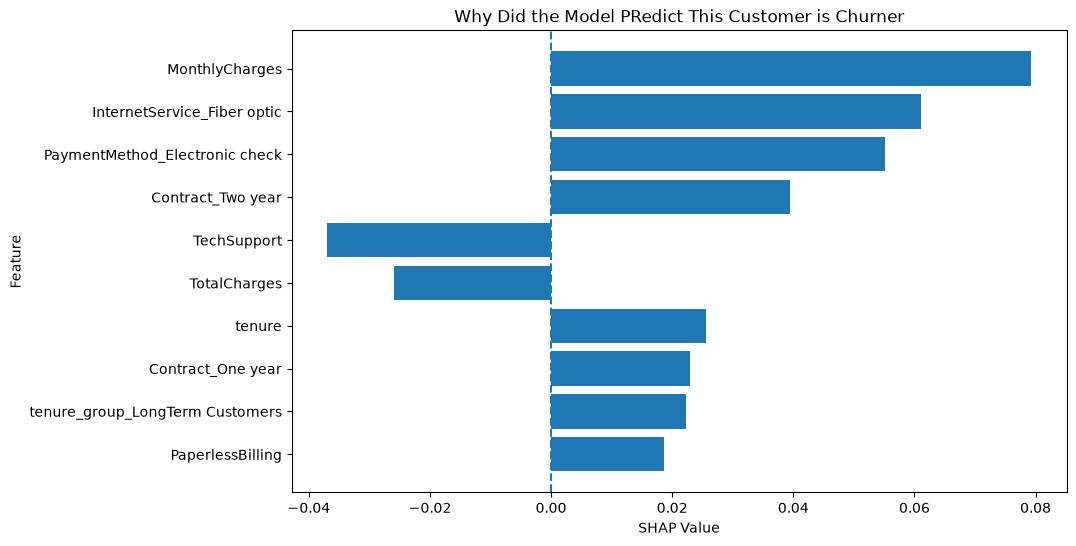

In [138]:
top_customer_features = individual_explanation.head(10)
plt.figure(figsize=(10, 6 ))

plt.barh(
    top_customer_features["Feature"][::-1],
    top_customer_features["SHAP_Value"][::-1]
)
plt.axvline(0,linestyle="--")
plt.xlabel("SHAP Value")
plt.ylabel("Feature")
plt.title("Why Did the Model PRedict This Customer is Churner")
plt.show()

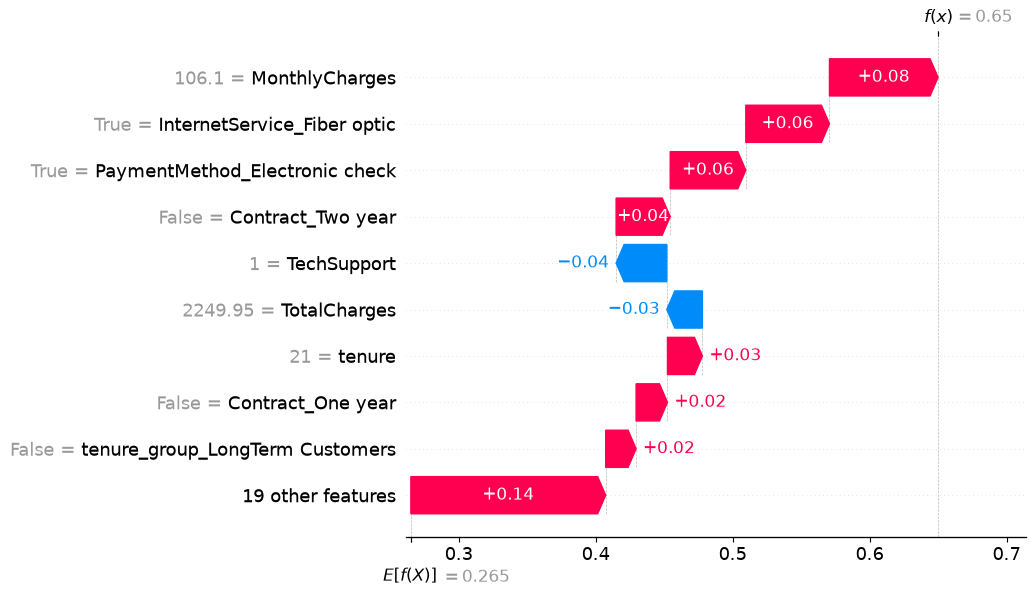

In [139]:
shap.plots.waterfall(
    shap.Explanation(
        values=customer_shap,
        base_values=explainer.expected_value[1]
            if isinstance(explainer.expected_value, (list, np.ndarray))
            else explainer.expected_value,
        data=customer.values,
        feature_names=x_test.columns
    )
)

In [140]:
customer_index_1 = 0
customer_index_2 = 1

for idx in [customer_index_1, customer_index_2]:

    explanation = pd.DataFrame({
        "Feature": x_test.columns,
        "SHAP_Value": shap_churn[idx]
    })

    explanation["Abs_SHAP"] = np.abs(
        explanation["SHAP_Value"]
    )

    explanation = explanation.sort_values(
        by="Abs_SHAP",
        ascending=False
    )

    print("\nCustomer:", idx)
    print(explanation.head(5))


Customer: 0
                           Feature  SHAP_Value  Abs_SHAP
14                  MonthlyCharges    0.079319  0.079319
18     InternetService_Fiber optic    0.061079  0.061079
21  PaymentMethod_Electronic check    0.055193  0.055193
17               Contract_Two year    0.039501  0.039501
10                     TechSupport   -0.037012  0.037012

Customer: 1
                           Feature  SHAP_Value  Abs_SHAP
4                           tenure    0.189906  0.189906
15                    TotalCharges    0.160296  0.160296
18     InternetService_Fiber optic    0.064765  0.064765
21  PaymentMethod_Electronic check    0.043361  0.043361
14                  MonthlyCharges    0.041150  0.041150


## Existing model ke reults ko LOCK karna 

In [141]:
results = pd.DataFrame({
    "Model":[
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        0.8003,
        0.7249,
        0.7775,
        0.7896
    ],
    "Precision": [
        0.6491,
        0.4866,
        0.6074,
        0.6328
    ],
    "Recall": [
        0.5544,
        0.4801,
        0.4801,
        0.5119
    ],
    "F1 Score": [
        0.5980,
        0.4833,
        0.5363,
        0.5660
    ]
})
results 

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8003,0.6491,0.5544,0.5980
1,Decision Tree,0.7249,0.4866,0.4801,0.4833
2,Random Forest,0.7775,0.6074,0.4801,0.5363
3,Tuned Random Forest,0.7896,0.6328,0.5119,0.5660


In [142]:
results.sort_values("F1 Score",ascending = False)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8003,0.6491,0.5544,0.5980
3,Tuned Random Forest,0.7896,0.6328,0.5119,0.5660
2,Random Forest,0.7775,0.6074,0.4801,0.5363
1,Decision Tree,0.7249,0.4866,0.4801,0.4833


### Cross Validation 

In [143]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv= StratifiedKFold(
    n_splits= 5,
    shuffle = True,
    random_state=69
)

In [144]:
cv_results = cross_validate(
    log_model,
    x,
    y,
    cv=cv,
    scoring=["accuracy","precision","recall","f1"]
)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:

In [145]:
log_model

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [146]:
log_model.set_params(max_iter=5000)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [147]:
log_cv = cross_validate(
    log_model,
    x,
    y,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

In [148]:
log_cv.keys()

dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_roc_auc'])

In [149]:
log_cv["test_accuracy"]

array([0.7981521 , 0.80810235, 0.80725462, 0.80156472, 0.80654339])

In [150]:
log_cv["test_precision"]

array([0.65100671, 0.67567568, 0.67346939, 0.65780731, 0.66887417])

In [151]:
log_cv["test_recall"]

array([0.51871658, 0.53475936, 0.5308311 , 0.52941176, 0.54010695])

In [152]:
log_cv["test_f1"]

array([0.57738095, 0.59701493, 0.59370315, 0.58666667, 0.59763314])

In [153]:
log_cv.keys()

dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_roc_auc'])

Average performance 

In [154]:
print("Mean Accuracy:", cv_results["test_accuracy"].mean())
print("Mean Precision:",cv_results["test_precision"].mean())
print("Mean Recall:",cv_results["test_recall"].mean())
print("Mean F1 Score:",cv_results["test_f1"].mean())


Mean Accuracy: 0.8036122981920311
Mean Precision: 0.6638536148923504
Mean Recall: 0.5291623059167609
Mean F1 Score: 0.588883721382703


In [155]:
rf_cv = cross_validate(
    rf_model,
    x,
    y,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"]
    
)

In [156]:
print("Mean Accuracy:", rf_cv["test_accuracy"].mean())
print("Mean Precision:", rf_cv["test_precision"].mean())
print("Mean Recall:", rf_cv["test_recall"].mean())
print("Mean F1:", rf_cv["test_f1"].mean())
print("Mean ROC-AUC:", rf_cv["test_roc_auc"].mean())

Mean Accuracy: 0.7895325243322102
Mean Precision: 0.6367147384135002
Mean Recall: 0.48528623245544866
Mean F1: 0.5507270597002483
Mean ROC-AUC: 0.822890741649023


## FINAL  MODEL COMPARISION 

In [157]:
log_pred= log_model.predict(x_test)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [158]:
dt_pred=dt_model.predict(x_test)

In [159]:
rf_pred = rf_model.predict(x_test)

In [160]:
from sklearn.metrics import accuracy_score, precision_score, recall_score 

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test,log_pred),
        accuracy_score(y_test,dt_pred),
        accuracy_score(y_test,rf_pred)
    ],
    "Precision":[
        precision_score(y_test,log_pred),
        precision_score(y_test,dt_pred),
        precision_score(y_test,rf_pred)
    ],
    "Recall":[
        recall_score(y_test,log_pred),
        recall_score(y_test,dt_pred),
        recall_score(y_test,rf_pred)
    ],
    "F1 Score":[
        f1_score(y_test,log_pred),
        f1_score(y_test,dt_pred),
        f1_score(y_test,rf_pred)
    ]
})
comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.267946,0.267946,1.000000,0.422646
1,Decision Tree,0.724947,0.486559,0.480106,0.483311
2,Random Forest,0.777541,0.607383,0.480106,0.536296


In [161]:
import numpy as np 
print("Log predictions:")
print(np.unique(log_pred, return_counts= True))

print("\nActual y_test:")
print(np.unique(y_test, return_counts=True))

Log predictions:
(array([1]), array([1407]))

Actual y_test:
(array([0, 1]), array([1030,  377]))


In [162]:
log_pred = log_model.predict(x_test_scaled)

print(np.unique(log_pred, return_counts=True))

(array([0, 1]), array([1085,  322]))


human logistic regression ke lia  pelha scaled data use kia thaa 
isilia x_test ki jagha x_test_scaled dena thaa 

In [163]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ],

    "Precision": [
        precision_score(y_test, log_pred),
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred)
    ],

    "Recall": [
        recall_score(y_test, log_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred)
    ],

    "F1 Score": [
        f1_score(y_test, log_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.800284,0.649068,0.554377,0.597997
1,Decision Tree,0.724947,0.486559,0.480106,0.483311
2,Random Forest,0.777541,0.607383,0.480106,0.536296


In [164]:
cv_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],

    "Accuracy_Mean": [
        log_cv["test_accuracy"].mean(),
        rf_cv["test_accuracy"].mean()
    ],

    "Precision_Mean": [
        log_cv["test_precision"].mean(),
        rf_cv["test_precision"].mean()
    ],

    "Recall_Mean": [
        log_cv["test_recall"].mean(),
        rf_cv["test_recall"].mean()
    ],

    "F1_Mean": [
        log_cv["test_f1"].mean(),
        rf_cv["test_f1"].mean()
    ],

    "ROC_AUC_Mean": [
        log_cv["test_roc_auc"].mean(),
        rf_cv["test_roc_auc"].mean()
    ]
})

cv_comparison.round(4)

,Model,Accuracy_Mean,Precision_Mean,Recall_Mean,F1_Mean,ROC_AUC_Mean
0,Logistic Regression,0.8043,0.6654,0.5308,0.5905,0.8458
1,Random Forest,0.7895,0.6367,0.4853,0.5507,0.8229


In [165]:
y_prob = log_model.predict_proba(x_test_scaled)[:, 1]

y_pred = (y_prob >= 0.5).astype(int)

error_df = x_test.copy()

error_df["Actual"] = y_test.values
error_df["Predicted"] = y_pred
error_df["Probability"] = y_prob

error_df["Error_Type"] = np.where(
    (error_df["Actual"] == 1) & (error_df["Predicted"] == 0),
    "False Negative",
    np.where(
        (error_df["Actual"] == 0) & (error_df["Predicted"] == 1),
        "False Positive",
        np.where(
            (error_df["Actual"] == 1) & (error_df["Predicted"] == 1),
            "True Positive",
            "True Negative"
        )
    )
)

error_df["Error_Type"].value_counts()

Error_Type
True Negative     917
True Positive     209
False Negative    168
False Positive    113
Name: count, dtype: int64

In [166]:
false_negatives = error_df[
    error_df["Error_Type"] == "False Negative"
]

false_negatives.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,PaymentMethod_Mailed check,tenure_group_Regular Customers,tenure_group_Loyal Customers,tenure_group_LongTerm Customers,MonthlyChargeBucket_Medium,MonthlyChargeBucket_High,Actual,Predicted,Probability,Error_Type
2877,0,0,1,1,61,1,1,0,1,0,...,False,False,False,True,False,True,1,0,0.389475,False Negative
4983,0,1,1,0,40,0,0,0,1,0,...,False,False,True,False,True,False,1,0,0.243996,False Negative
1664,0,0,0,0,46,1,1,0,0,0,...,False,False,True,False,False,True,1,0,0.316080,False Negative
6507,0,0,1,1,58,1,1,1,1,0,...,False,False,False,True,False,True,1,0,0.236977,False Negative
3262,0,0,1,1,34,1,1,0,0,1,...,False,False,True,False,False,True,1,0,0.382447,False Negative


In [167]:
false_negatives.shape

(168, 32)

In [168]:
false_negatives[
    ["Actual", "Predicted", "Probability"]
].head(10)

,Actual,Predicted,Probability
2877,1,0,0.389475
4983,1,0,0.243996
1664,1,0,0.316080
6507,1,0,0.236977
3262,1,0,0.382447
1057,1,0,0.474701
5049,1,0,0.280742
1268,1,0,0.245148
2297,1,0,0.236637
4146,1,0,0.442188


In [169]:
false_positives = error_df[error_df["Error_Type"] == "False Positive"]
false_positives.shape

(113, 32)

In [170]:
false_positives[
    ["Actual", "Predicted", "Probability"]
].head(10)

,Actual,Predicted,Probability
4514,0,1,0.516024
329,0,1,0.571075
5716,0,1,0.573599
2781,0,1,0.597922
2171,0,1,0.525512
352,0,1,0.784131
1089,0,1,0.516455
3731,0,1,0.752570
741,0,1,0.625596
5372,0,1,0.583479


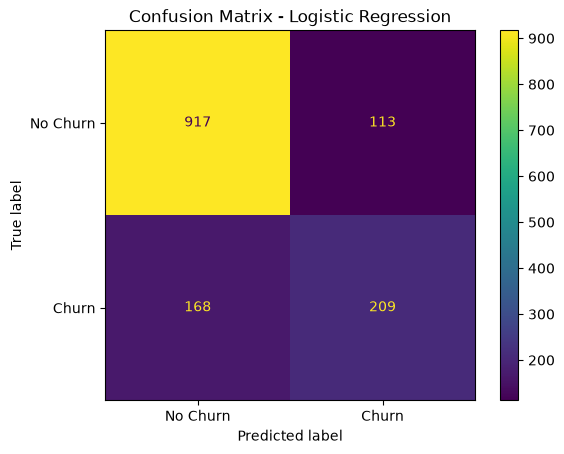

In [171]:
from sklearn.metrics import confusion_matrix , ConfusionMatrixDisplay
import matplotlib.pyplot as plt 

cm = confusion_matrix(y_test , y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [172]:
thresholds = [0.3 , 0.4 , 0.5 , 0.6 , 0.7]
threshold_analysis = [] 
for threshold in thresholds:
    pred = (y_prob >= threshold).astype(int)
    tn , fp , fn , tp = confusion_matrix(y_test,pred).ravel()

    threshold_analysis.append({
        "Threshold": threshold,
        "TN": tn , 
        "FP": fp , 
        "FN": fn , 
        "TP": tp , 
        "Precision": tp/ (tp+fp),
        "Recall": tp/(tp+fn),
        "FNR": fn / (fn+tp)

    })
threshold_analysis_df = pd.DataFrame(threshold_analysis)
threshold_analysis_df.round(4)

,Threshold,TN,FP,FN,TP,Precision,Recall,FNR
0,0.3,771,259,86,291,0.5291,0.7719,0.2281
1,0.4,848,182,124,253,0.5816,0.6711,0.3289
2,0.5,917,113,168,209,0.6491,0.5544,0.4456
3,0.6,969,61,232,145,0.7039,0.3846,0.6154
4,0.7,1007,23,285,92,0.8000,0.2440,0.7560


## Business Cost simulation 
False Negative = 2000 
False positive = 500 

In [173]:
FN_COST = 2000 
FP_COST = 500 

threshold_analysis_df["Business_Cost"]= (
    threshold_analysis_df["FN"]* FN_COST
    + threshold_analysis_df["FP"]* FP_COST
)

threshold_analysis_df[
    ["Threshold", "FP", "FN" , "Recall" , "Business_Cost"]
].sort_values("Business_Cost")



,Threshold,FP,FN,Recall,Business_Cost
0,0.3,259,86,0.771883,301500
1,0.4,182,124,0.671088,339000
2,0.5,113,168,0.554377,392500
3,0.6,61,232,0.384615,494500
4,0.7,23,285,0.244032,581500


## Conclusion

This project developed an end-to-end customer churn prediction system.

Multiple classification models were evaluated, including Logistic Regression,
Decision Tree, and Random Forest.

Logistic Regression achieved the strongest overall performance on the test set,
with an accuracy of 80.03%, precision of 64.91%, recall of 55.44%, and F1 score
of 59.80%.

Model explainability using SHAP showed that features such as tenure,
InternetService_Fiber optic, Contract type, TotalCharges, PaymentMethod_Electronic
check, and MonthlyCharges were among the important contributors to model
predictions.

Threshold tuning showed that reducing the classification threshold from 0.5
to 0.3 increased recall from approximately 55% to 77%, which may be useful when
the business objective is to identify more customers at risk of churn.

The final threshold should therefore be selected based on the business cost of
false positives versus false negatives.

The roadmap's required recommendations include:

Prioritize customers with high predicted churn probability for retention campaigns.
Use a lower threshold when the cost of missing a churner is high.
Use SHAP to understand individual churn predictions.
Don't interpret feature importance as causality.
Evaluate retention campaigns using retention rate, incremental revenue, campaign cost and CLV.
Adjust threshold according to retention budget and relative FP/FN costs


The goal is:

"Let's identify customers who are most likely to churn and use the available retention budget where it can have the most impact."

So the workflow would be:

1. Identify high-risk churners
→ Model gives churn probability.

2. Understand why they are high-risk
→ Use SHAP to understand which features contributed to that particular prediction.

3. Take a targeted retention action
For example:

special offer
discount
better plan
technical support
contract incentive
address their service/payment issue

4. Measure whether the intervention actually worked
→ retention rate, incremental revenue, campaign cost, CLV, etc

# Final Model Performance Table 

In [174]:
final_model_comparison = pd.DataFrame({
    "Model": [ 
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        0.8003,
        0.7249,
        0.7775,
        0.7896
    ], 
    "Precision": [
        0.6491,
        0.4866,
        0.6074,
        0.6328
    ],
    "Recall": [
        0.5544,
        0.4801,
        0.4801,
        0.5119
    ],
    "F1 Score":[
        0.5980,
        0.4833,
        0.5363,
        0.5660
    ]
})

final_model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8003,0.6491,0.5544,0.5980
1,Decision Tree,0.7249,0.4866,0.4801,0.4833
2,Random Forest,0.7775,0.6074,0.4801,0.5363
3,Tuned Random Forest,0.7896,0.6328,0.5119,0.5660


In [175]:
final_model_comparison.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8003,0.6491,0.5544,0.5980
3,Tuned Random Forest,0.7896,0.6328,0.5119,0.5660
2,Random Forest,0.7775,0.6074,0.4801,0.5363
1,Decision Tree,0.7249,0.4866,0.4801,0.4833


In [176]:
threshold_analysis_df.round(4)

,Threshold,TN,FP,FN,TP,Precision,Recall,FNR,Business_Cost
0,0.3,771,259,86,291,0.5291,0.7719,0.2281,301500
1,0.4,848,182,124,253,0.5816,0.6711,0.3289,339000
2,0.5,917,113,168,209,0.6491,0.5544,0.4456,392500
3,0.6,969,61,232,145,0.7039,0.3846,0.6154,494500
4,0.7,1007,23,285,92,0.8000,0.2440,0.7560,581500


Threshold Track-off graph 

<function matplotlib.pyplot.show(close=None, block=None)>

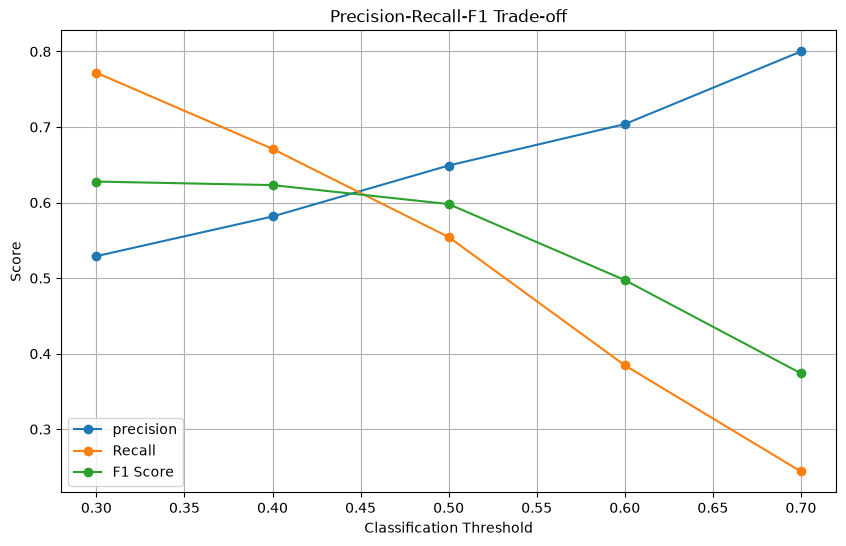

In [177]:
plt.figure(figsize=(10,6))
plt.plot(
    threshold_analysis_df["Threshold"],
    threshold_analysis_df["Precision"],
    marker="o",
    label="precision"
)
plt.plot(
    threshold_analysis_df["Threshold"],
    threshold_analysis_df["Recall"],
    marker="o",
    label="Recall"
)

# Calaculate F1 for each Threshold 
f1_values = (
    2 * threshold_analysis_df["Precision"]
    * threshold_analysis_df["Recall"]
    / (threshold_analysis_df["Precision"]
       + threshold_analysis_df["Recall"])
)
plt.plot(
    threshold_analysis_df["Threshold"],
    f1_values,
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall-F1 Trade-off")
plt.legend()
plt.grid(True)

plt.show

In [178]:
risk_df = x_test.copy()
risk_df["Churn_Probability"] = y_prob
risk_df[["Churn_Probability"]].head(10)


,Churn_Probability
6550,0.591403
4353,0.722127
2877,0.389475
2555,0.402671
350,0.022354
5104,0.016901
1654,0.098072
3220,0.009809
3461,0.058768
4983,0.243996


In [179]:
risk_df["Churn_Probability"].describe()

count    1407.000000
mean        0.271233
std         0.250229
min         0.002036
25%         0.039173
50%         0.205163
75%         0.464030
max         0.871849
Name: Churn_Probability, dtype: float64

In [180]:
risk_df["Risk_Level"]= pd.cut(
    risk_df["Churn_Probability"],
    bins=[0,0.3,0.6,1],
    labels=["Low Risk", "Medium Risk", "High Risk"],
    include_lowest=True
)

risk_df["Risk_Level"].value_counts()

Risk_Level
Low Risk       857
Medium Risk    344
High Risk      206
Name: count, dtype: int64

In [181]:
risk_df["Risk_Level"].value_counts(normalize=True).round(4) * 100 

Risk_Level
Low Risk       60.91
Medium Risk    24.45
High Risk      14.64
Name: proportion, dtype: float64

## Retention Strategy by Risk Level

###  High Risk
- Prioritize for immediate retention intervention.
- Review the factors contributing to the customer's predicted churn.
- Use SHAP explanations for individual customer analysis.
- Provide personalized offers, discounts, service support, or plan adjustments where appropriate.
- Monitor whether the intervention successfully prevents churn.

###  Medium Risk
- Use preventive engagement strategies.
- Monitor customer behavior and churn probability.
- Provide personalized communication and targeted incentives when appropriate.
- Escalate customers to high-risk treatment if their predicted risk increases.

###  Low Risk
- Continue normal customer engagement.
- Avoid unnecessary high-cost retention campaigns.
- Monitor risk periodically for changes.

In [182]:
high_risk_customers = risk_df[
    risk_df["Risk_Level"] == "High Risk"
].copy()

high_risk_customers = high_risk_customers.sort_values(
    by="Churn_Probability",
    ascending = False 
)

high_risk_customers[
    ["Churn_Probability","Risk_Level"]
].head(10)

,Churn_Probability,Risk_Level
3749,0.871849,High Risk
2208,0.871378,High Risk
4585,0.854646,High Risk
6482,0.854268,High Risk
5933,0.850757,High Risk
2184,0.848056,High Risk
2797,0.842784,High Risk
969,0.842664,High Risk
1148,0.842624,High Risk
6862,0.835879,High Risk


In [183]:
high_risk_customers.shape


(206, 30)

## Business Idea

The main objective of this project is not only to predict which customers are likely to churn, but also to help the company take action before the customer leaves.

The model can identify customers with a high probability of churn and divide them into different risk levels. High-risk customers can then be prioritized by the retention team.

For each high-risk customer, the company can use the model explanations to understand which factors contributed to the churn prediction. Based on these factors, the company can provide a suitable retention action, such as a special offer, discount, better plan, technical support, or another personalized solution.

For example, if a customer has a high predicted churn probability because of factors related to their service or payment experience, the company can investigate that issue and provide an appropriate solution instead of giving the same offer to every customer.

This creates a more targeted retention strategy where the company focuses its resources on customers who are more likely to leave and provides them with solutions based on their individual situation.

The success of the retention strategy should then be measured using metrics such as retention rate, incremental revenue, campaign cost, and customer lifetime value.

## Final Project Story

Customer churn is an important business problem because losing an existing customer can affect the company's revenue and customer relationships. The objective of this project was to build a machine learning system that can identify customers who are more likely to churn and help the company take preventive action.

The project started with data exploration and preprocessing. Missing values, duplicate records, categorical variables, and numerical features were analyzed and prepared for machine learning.

Multiple classification models were then evaluated, including Logistic Regression, Decision Tree, and Random Forest. Logistic Regression gave the strongest overall performance among the tested models, with an F1 score of approximately 59.8% on the test set.

Instead of looking only at accuracy, the project focused on precision, recall, F1 score, ROC-AUC, and the confusion matrix because missing an actual churner can be costly for the business.

The classification threshold was also analyzed. Lowering the threshold from 0.5 to 0.3 increased recall from approximately 55% to 77%, which allowed the model to identify more potential churners. A hypothetical business cost analysis also showed that a threshold of 0.3 produced the lowest cost under the assumed false-negative and false-positive costs.

The model was then used to generate churn probabilities for individual customers. These probabilities were converted into Low, Medium, and High Risk groups. Out of 1,407 test customers, 206 were classified as High Risk.

The final goal is not simply to predict churn. The high-risk customers can be investigated further to understand the factors contributing to their predictions, and the company can then provide suitable retention actions such as special offers, discounts, better plans, or additional support.

This creates a complete business workflow:

Customer Data → Churn Prediction → Risk Score → Risk Segmentation → Customer-Level Analysis → Retention Action → Business Evaluation

The effectiveness of the retention strategy should finally be measured using business metrics such as retention rate, incremental revenue, campaign cost, and customer lifetime value.

In [184]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Model",
        "Test Accuracy",
        "Test Precision",
        "Test Recall",
        "Test F1 Score",
        "ROC-AUC",
        "Selected Threshold",
        "High-Risk Customers",
        "High-Risk Percentage",
        "Lowest Hypothetical Business Cost"
    ],

    "Value": [
        "Logistic Regression",
        0.8003,
        0.6491,
        0.5544,
        0.5980,
        0.846,
        0.3,
        206,
        14.64,
        "₹3,01,500"
    ]
})

final_metrics

,Metric,Value
0,Model,Logistic Regression
1,Test Accuracy,0.8003
2,Test Precision,0.6491
3,Test Recall,0.5544
4,Test F1 Score,0.598
5,ROC-AUC,0.846
6,Selected Threshold,0.3
7,High-Risk Customers,206
8,High-Risk Percentage,14.64
9,Lowest Hypothetical Business Cost,"₹3,01,500"


## Business KPIs

The success of the churn prediction system should not be measured only using machine learning metrics. The company should also track business KPIs to understand whether the retention strategy is actually helping.

### 1. Retention Rate

Measures the percentage of targeted customers who continue using the service after the retention campaign.

### 2. Churn Reduction

Measures whether the number or percentage of customers leaving the company decreases after implementing the retention strategy.

### 3. Incremental Revenue

Measures the additional revenue generated because customers were successfully retained.

### 4. Campaign Cost

Measures how much the company spends on discounts, offers, support, and other retention activities.

### 5. Customer Lifetime Value (CLV)

Measures the expected value of a customer over their relationship with the company. High-value customers may deserve higher priority when planning retention campaigns.

### 6. Retention Campaign ROI

Compares the financial benefit generated from successfully retained customers with the cost of running the retention campaign.

Overall, the model should be considered successful only if its predictions help the company make better retention decisions and generate measurable business value.

## Limitations

There are some limitations to this customer churn prediction project.

1. The model is trained on historical customer data, so its performance may change if customer behavior or business conditions change over time.

2. The selected threshold of 0.3 is based on the hypothetical false-negative and false-positive costs used in this project. A real company would need to determine these costs using actual business data.

3. The model predicts the probability of churn, but it does not prove that a particular feature is the actual cause of a customer leaving.

4. SHAP is useful for understanding which features contributed to a model prediction, but these explanations should not be treated as causal relationships.

5. The risk categories and retention strategies used in this project are based on the available dataset and may need to be adjusted for a real company's customer base and retention budget.

6. The effectiveness of the retention strategy cannot be confirmed using the prediction model alone. The company would need to run retention campaigns and measure whether customers were actually retained and whether the campaign generated positive business value.

7. The hypothetical business cost analysis uses assumed costs for false negatives and false positives. Actual costs may be different for a real company.